Dataset Loaded Successfully!
Dataset Shape: (569, 30)
Target Classes: ['malignant' 'benign']

Training Samples: 455
Testing Samples: 114

------------------------------
MODEL: Logistic Regression
-------------------------------
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



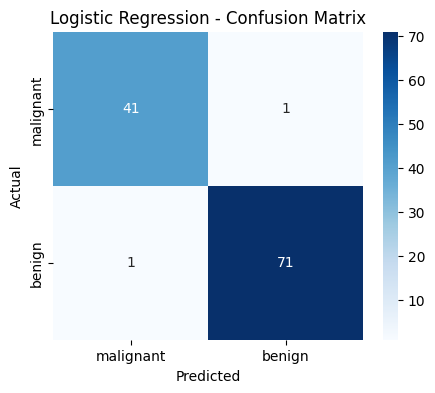


------------------------------
MODEL: Decision Tree
-------------------------------
              precision    recall  f1-score   support

   malignant       0.91      0.93      0.92        42
      benign       0.96      0.94      0.95        72

    accuracy                           0.94       114
   macro avg       0.93      0.94      0.93       114
weighted avg       0.94      0.94      0.94       114



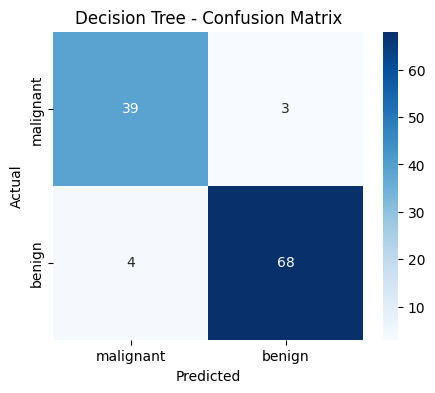


------------------------------
MODEL: KNN
-------------------------------
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



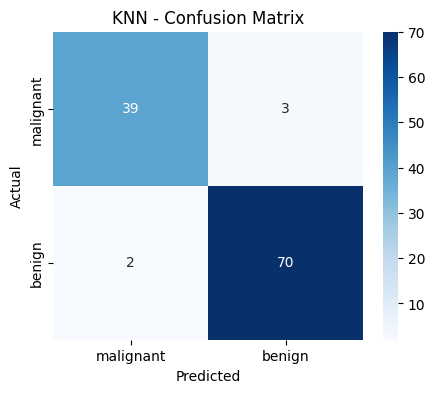


------------------------------
MODEL: Stacking
-------------------------------
              precision    recall  f1-score   support

   malignant       1.00      0.95      0.98        42
      benign       0.97      1.00      0.99        72

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



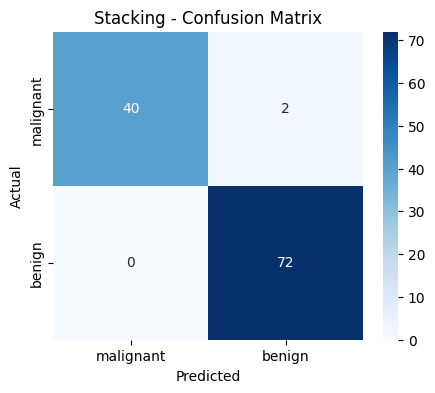


------------------------------
MODEL: AdaBoost
-------------------------------
              precision    recall  f1-score   support

   malignant       0.97      0.90      0.94        42
      benign       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



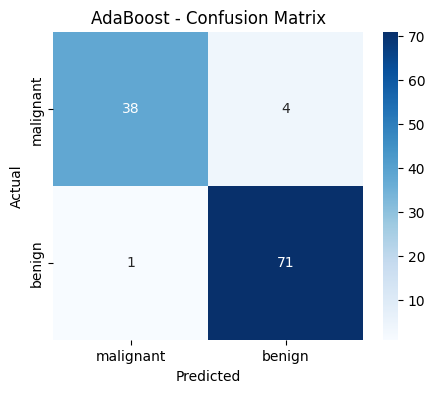


------------------------------
MODEL: Voting
-------------------------------
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



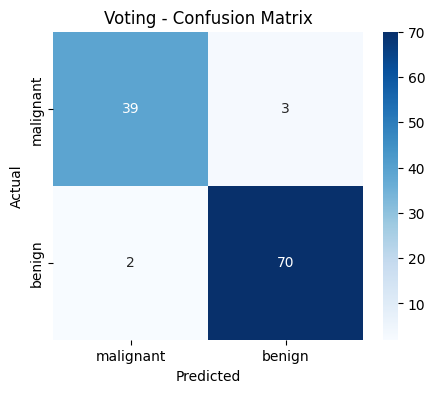


FINAL PERFORMANCE COMPARISON
              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
Logistic Regression    0.9825     0.9861  0.9861    0.9861   0.9954
      Decision Tree    0.9386     0.9577  0.9444    0.9510   0.9342
                KNN    0.9561     0.9589  0.9722    0.9655   0.9788
           Stacking    0.9825     0.9730  1.0000    0.9863   0.9921
           AdaBoost    0.9561     0.9467  0.9861    0.9660   0.9835
             Voting    0.9561     0.9589  0.9722    0.9655   0.9897


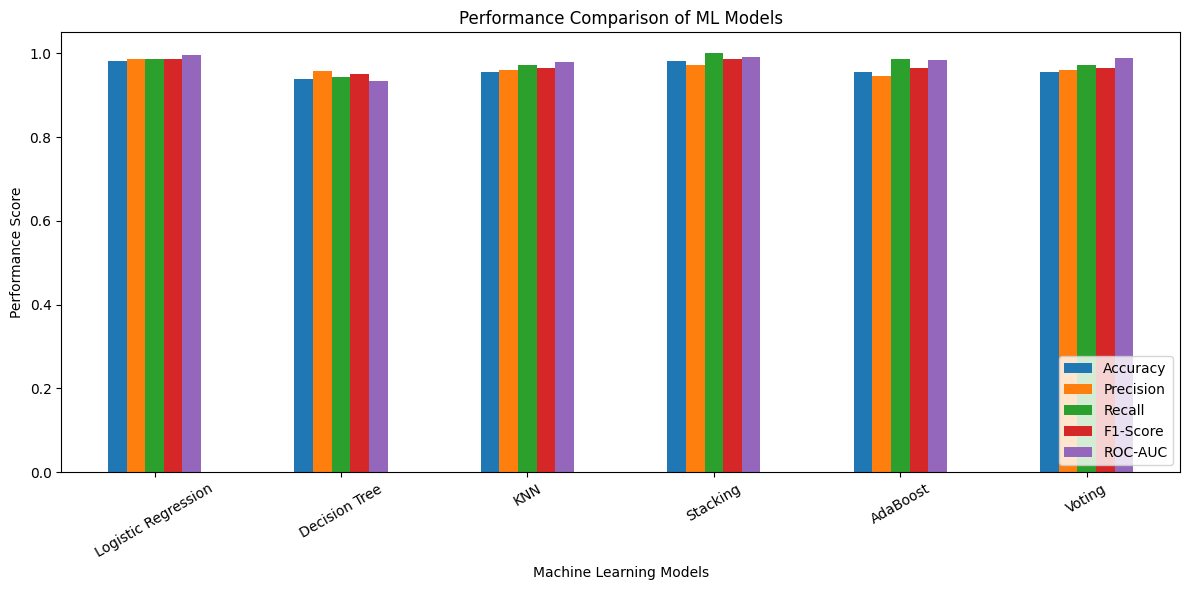


BEST MODEL BASED ON F1-SCORE
Model        Stacking
Accuracy     0.982456
Precision    0.972973
Recall            1.0
F1-Score     0.986301
ROC-AUC      0.992063
All Base and Ensemble Models Evaluated.


In [2]:
# Ensemble Learning and Performance Evaluation

# 1. Imported Required Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.ensemble import (
    StackingClassifier,
    AdaBoostClassifier,
    VotingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)


# 2. Load Dataset

data = load_breast_cancer()

X = data.data
y = data.target

print("Dataset Loaded Successfully!")
print("Dataset Shape:", X.shape)
print("Target Classes:", data.target_names)


# 3. Split Dataset into Training and Testing Sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))


# 4. Create Base Classifiers

lr = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=5000))
])

dt = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

knn = Pipeline([
    ('scaler', StandardScaler()),
    ('model', KNeighborsClassifier(n_neighbors=5))
])


# 5. Store Individual Models

models = {
    "Logistic Regression": lr,
    "Decision Tree": dt,
    "KNN": knn
}


# 6. Implement Stacking Classifier

stacking = StackingClassifier(
    estimators=[
        ('lr', lr),
        ('dt', dt),
        ('knn', knn)
    ],
    final_estimator=LogisticRegression(max_iter=5000),
    cv=5
)


# 7. Implement AdaBoost Classifier

adaboost = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=1,
        random_state=42
    ),
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)


# 8. Implement Voting Classifier (Soft Voting)

voting = VotingClassifier(
    estimators=[
        ('lr', lr),
        ('dt', dt),
        ('knn', knn)
    ],
    voting='soft'
)


# 9. Add Ensemble Models

models["Stacking"] = stacking
models["AdaBoost"] = adaboost
models["Voting"] = voting


# 10. Train Models and Evaluate Performance

results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    y_prob = model.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_prob)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": auc
    })

    print("\n------------------------------")
    print("MODEL:", name)
    print("-------------------------------")

    print(classification_report(
        y_test,
        y_pred,
        target_names=data.target_names
    ))

    # Confusion Matrix

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=data.target_names,
        yticklabels=data.target_names
    )

    plt.title(name + " - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()


# 11. Display Performance Comparison Table

results_df = pd.DataFrame(results)

print("\nFINAL PERFORMANCE COMPARISON")

print(results_df.round(4).to_string(index=False))


# 12. Visualize Performance Comparison

results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title("Performance Comparison of ML Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Performance Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=30)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


# 13. Identify Best Performing Model

best_model = results_df.loc[
    results_df["F1-Score"].idxmax()
]

print("\nBEST MODEL BASED ON F1-SCORE")
print(best_model.to_string())

print("All Base and Ensemble Models Evaluated.")